<a href="https://colab.research.google.com/github/roopeshscs24-maker/BIS-lab/blob/main/ResourceSchedulingACO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install numpy matplotlib -q


===== OPTIMAL RESOURCE SCHEDULE =====
T1 -> R3 | Duration: 3 hours
T2 -> R5 | Duration: 2 hours
T3 -> R4 | Duration: 4 hours
T4 -> R1 | Duration: 5 hours
T5 -> R3 | Duration: 3 hours
T6 -> R2 | Duration: 2 hours
T7 -> R2 | Duration: 4 hours
T8 -> R5 | Duration: 3 hours

===== RESOURCE UTILIZATION =====
R1 Workload: 5.0 hours | Utilization: 50.0 %
R2 Workload: 6.0 hours | Utilization: 60.0 %
R3 Workload: 6.0 hours | Utilization: 60.0 %
R4 Workload: 4.0 hours | Utilization: 40.0 %
R5 Workload: 5.0 hours | Utilization: 50.0 %

Minimum Scheduling Cost: 17.15


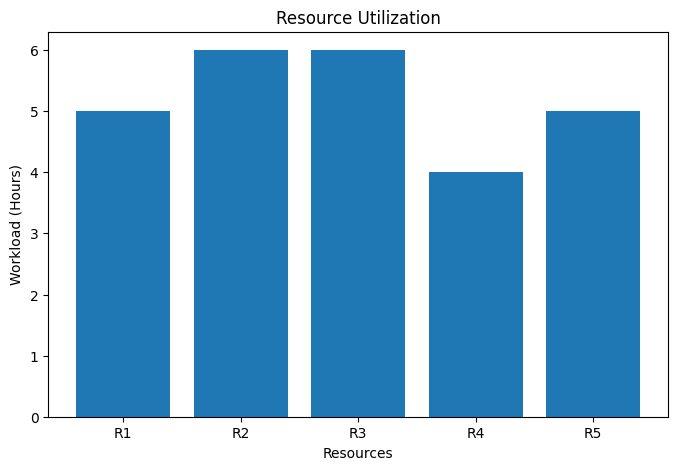

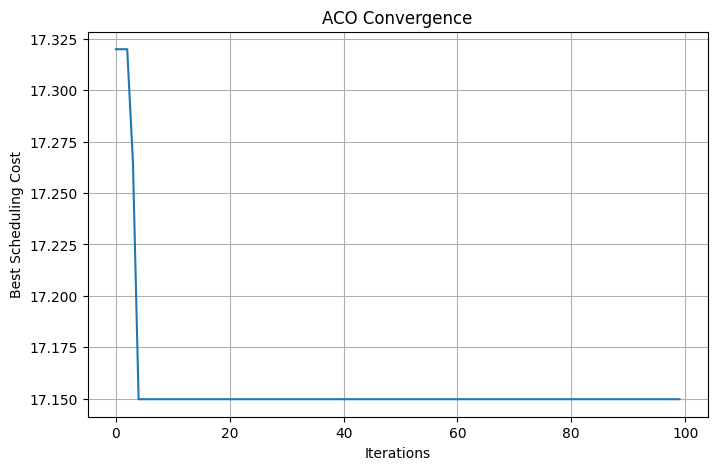

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. INPUT PARAMETERS
# ==========================================

resources = ["R1", "R2", "R3", "R4", "R5"]

tasks = ["T1", "T2", "T3", "T4",
         "T5", "T6", "T7", "T8"]

# Task execution time (hours)
duration = np.array([3, 2, 4, 5, 3, 2, 4, 3])

# Resource capacity (maximum workload in hours)
capacity = np.array([10, 10, 10, 10, 10])

# Resource availability (hours)
availability = np.array([10, 10, 10, 10, 10])

# Task dependencies
# T3 depends on T1
# T4 depends on T2
# T5 depends on T3
# T6 depends on T4
# T7 depends on T5 and T6
# T8 depends on T7

dependencies = {
    0: [],
    1: [],
    2: [0],
    3: [1],
    4: [2],
    5: [3],
    6: [4, 5],
    7: [6]
}

n_tasks = len(tasks)
n_resources = len(resources)

# ==========================================
# 2. ACO PARAMETERS
# ==========================================

ants = 30
iterations = 100

alpha = 1
beta = 2
evaporation = 0.5
Q = 100

# Pheromone initialization
pheromone = np.ones((n_tasks, n_resources))

# Heuristic information
heuristic = np.zeros((n_tasks, n_resources))

for i in range(n_tasks):
    for j in range(n_resources):
        heuristic[i][j] = 1 / (duration[i] / capacity[j])

# ==========================================
# 3. FITNESS FUNCTION
# ==========================================

def calculate_fitness(solution):

    workload = np.zeros(n_resources)

    for i in range(n_tasks):
        resource = solution[i]
        workload[resource] += duration[i]

    # Check resource capacity
    if np.any(workload > capacity):
        return float('inf')

    # Check resource availability
    if np.any(workload > availability):
        return float('inf')

    # Calculate workload imbalance
    imbalance = np.std(workload)

    # Project completion time considering dependencies
    finish = np.zeros(n_tasks)

    resource_finish = np.zeros(n_resources)

    for i in range(n_tasks):

        r = solution[i]

        dependency_finish = max(
            [finish[d] for d in dependencies[i]],
            default=0
        )

        start = max(
            dependency_finish,
            resource_finish[r]
        )

        finish[i] = start + duration[i]

        resource_finish[r] = finish[i]

    makespan = np.max(finish)

    return makespan + 0.2 * imbalance


# ==========================================
# 4. ANT COLONY OPTIMIZATION
# ==========================================

best_solution = None
best_cost = float('inf')

cost_history = []

for iteration in range(iterations):

    all_solutions = []
    all_costs = []

    for ant in range(ants):

        solution = []

        workload = np.zeros(n_resources)

        for i in range(n_tasks):

            # Calculate resource selection probability
            probability = (
                pheromone[i] ** alpha
                * heuristic[i] ** beta
            )

            # Remove overloaded resources
            for j in range(n_resources):
                if workload[j] + duration[i] > capacity[j]:
                    probability[j] = 0

            if np.sum(probability) == 0:
                solution = None
                break

            probability = probability / np.sum(probability)

            # Select resource
            selected = np.random.choice(
                n_resources,
                p=probability
            )

            solution.append(selected)

            workload[selected] += duration[i]

        if solution is not None:

            cost = calculate_fitness(solution)

            all_solutions.append(solution)
            all_costs.append(cost)

            if cost < best_cost:
                best_cost = cost
                best_solution = solution.copy()

    # Pheromone evaporation
    pheromone *= (1 - evaporation)

    # Pheromone update
    for solution, cost in zip(all_solutions, all_costs):

        if np.isfinite(cost):

            for i in range(n_tasks):

                r = solution[i]

                pheromone[i][r] += Q / cost

    cost_history.append(best_cost)

# ==========================================
# 5. DISPLAY OPTIMAL SCHEDULE
# ==========================================

print("\n===== OPTIMAL RESOURCE SCHEDULE =====")

if best_solution is not None:

    workload = np.zeros(n_resources)

    for i in range(n_tasks):

        r = best_solution[i]

        workload[r] += duration[i]

        print(
            tasks[i],
            "->",
            resources[r],
            "| Duration:",
            duration[i],
            "hours"
        )

    print("\n===== RESOURCE UTILIZATION =====")

    for i in range(n_resources):

        utilization = (
            workload[i] / availability[i]
        ) * 100

        print(
            resources[i],
            "Workload:",
            workload[i],
            "hours | Utilization:",
            round(utilization, 2),
            "%"
        )

    print("\nMinimum Scheduling Cost:", round(best_cost, 2))

    # ======================================
    # 6. RESOURCE UTILIZATION GRAPH
    # ======================================

    plt.figure(figsize=(8, 5))

    plt.bar(resources, workload)

    plt.xlabel("Resources")
    plt.ylabel("Workload (Hours)")

    plt.title("Resource Utilization")

    plt.show()

    # ======================================
    # 7. ACO CONVERGENCE GRAPH
    # ======================================

    plt.figure(figsize=(8, 5))

    plt.plot(cost_history)

    plt.xlabel("Iterations")
    plt.ylabel("Best Scheduling Cost")

    plt.title("ACO Convergence")

    plt.grid(True)

    plt.show()

else:
    print("No feasible schedule found.")